# Five-year mortality prediction in endometrial carcinoma (TCGA-UCEC)

Notebook for the capstone project of the MBA in Artificial Intelligence and Big Data (ICMC-USP).

**Question:** does tumor gene expression predict death within 5 years, once censoring is handled and data leakage is avoided?

**Structure**
1. Setup and data loading
2. Outcome definition with censoring correction
3. Train/test split and feature sets
4. Models (LASSO, Random Forest, XGBoost, SVM, RF variants)
5. Performance comparison and statistical tests (McNemar, bootstrap)
6. Most important genes
7. Thesis figures
8. Robustness analysis: AWST vs log2(TPM+1) normalization
9. Appendix: risk scores on the GSE106191 cohort (exploratory, not part of the thesis)

Data are not included in the repository. See `README.md` for how to obtain them. Code comments and figure labels are in Portuguese, matching the thesis.

## 1. Setup and data loading

In [25]:
# ============================================================
# Etapa 1: CONFIGURACAO INICIAL
# ============================================================

%pip install -q imbalanced-learn xgboost statsmodels

# Funciona no Colab (dados no Google Drive) e localmente (pasta data/)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    caminho = '/content/drive/MyDrive/MBA_Dados/'
except ImportError:
    caminho = 'data/'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import time
import json
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              roc_curve, average_precision_score, precision_recall_curve)
from sklearn.impute import SimpleImputer
from sklearn.utils import resample
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import xgboost as xgb
from statsmodels.stats.contingency_tables import mcnemar

RANDOM_STATE = 42
print("Configuracao concluida.")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Configuracao concluida.


In [26]:
# ============================================================
# Etapa 2: CARREGAR DADOS BASE
# ============================================================

with open(caminho + 'exprData.pkl', 'rb') as f:
    exprData = pickle.load(f)

with open(caminho + 'clin_f.pkl', 'rb') as f:
    clin_f = pickle.load(f)

print(f"exprData original: {exprData.shape}")
print(f"clin_f original: {clin_f.shape}")

exprData original: (522, 10164)
clin_f original: (522, 39)


## 2. Outcome with censoring correction
Only patients with a known 5-year status are kept: death at any time, or follow-up of at least 60 months.

In [27]:
# ============================================================
# Etapa 3: DEFINIR DESFECHO COM CORRECAO DE CENSURA
# Paciente so entra na analise se o status em 5 anos e conhecido:
# morreu (a qualquer momento) OU foi acompanhado por >= 60 meses.
# ============================================================

clin_f['OS_MONTHS_num'] = pd.to_numeric(clin_f['OS_MONTHS'], errors='coerce')

clin_f['STATUS_5Y_CONFIRMADO'] = (
    (clin_f['OS_STATUS'] == '1:DECEASED') |
    (clin_f['OS_MONTHS_num'] >= 60)
)

clin_f_valid = clin_f[clin_f['STATUS_5Y_CONFIRMADO']].copy()

clin_f_valid['OS_STATUS_5y'] = (
    (clin_f_valid['OS_STATUS'] == '1:DECEASED') &
    (clin_f_valid['OS_MONTHS_num'] <= 60)
).astype(int)

clin_f_valid = clin_f_valid.set_index('PATIENT_ID')

print(f"Coorte original: {clin_f.shape[0]} pacientes")
print(f"Coorte com desfecho de 5 anos confirmado: {clin_f_valid.shape[0]} pacientes")
print(clin_f_valid['OS_STATUS_5y'].value_counts())
print(f"Proporcao de obitos: {clin_f_valid['OS_STATUS_5y'].mean():.4f}")

pacientes_validos = clin_f_valid.index
exprData_valid = exprData.loc[pacientes_validos]
print(f"exprData apos filtro: {exprData_valid.shape}")


Coorte original: 522 pacientes
Coorte com desfecho de 5 anos confirmado: 183 pacientes
OS_STATUS_5y
0    104
1     79
Name: count, dtype: int64
Proporcao de obitos: 0.4317
exprData apos filtro: (183, 10164)


## 3. Train/test split and feature sets
A single master split (70/30, stratified, seed 42) is shared by all models.

In [28]:
# ============================================================
# Etapa 4: SPLIT MESTRE UNICO (reutilizado em todos os modelos)
# Evita qualquer risco de desalinhamento entre y_test de modelos
# diferentes, ja que todo mundo deriva do mesmo idx_train/idx_test.
# ============================================================

y = clin_f_valid['OS_STATUS_5y']

idx_train, idx_test = train_test_split(
    clin_f_valid.index, test_size=0.3, stratify=y, random_state=RANDOM_STATE
)

y_train = y.loc[idx_train]
y_test = y.loc[idx_test]

X_train = exprData_valid.loc[idx_train]
X_test = exprData_valid.loc[idx_test]

print(f"Treino: {X_train.shape[0]} amostras ({y_train.sum()} obitos)")
print(f"Teste:  {X_test.shape[0]} amostras ({y_test.sum()} obitos)")


Treino: 128 amostras (55 obitos)
Teste:  55 amostras (24 obitos)


In [29]:
# ============================================================
# Etapa 5: PREPARAR CONJUNTOS DE FEATURES DERIVADOS
# (top 1000 genes, clinicas, combinado) -- tudo fatiado do
# mesmo idx_train / idx_test da Celula 4.
# ============================================================

# --- top 1000 genes por variancia, calculada SO no treino ---
variancias = X_train.var()
top_genes = variancias.nlargest(1000).index
X_train_top = X_train[top_genes]
X_test_top = X_test[top_genes]

# --- variaveis clinicas ---
variaveis_clinicas = ['AGE', 'RADIATION_THERAPY', 'SUBTYPE']
X_clin_full = clin_f_valid[variaveis_clinicas].copy()

for col in ['RADIATION_THERAPY', 'SUBTYPE']:
    if X_clin_full[col].dtype == 'object':
        le = LabelEncoder()
        X_clin_full[col] = le.fit_transform(X_clin_full[col].astype(str))

X_clin_train_raw = X_clin_full.loc[idx_train]
X_clin_test_raw = X_clin_full.loc[idx_test]

imputer_clin = SimpleImputer(strategy='median')
X_clin_train = pd.DataFrame(
    imputer_clin.fit_transform(X_clin_train_raw),
    index=X_clin_train_raw.index, columns=X_clin_train_raw.columns
)
X_clin_test = pd.DataFrame(
    imputer_clin.transform(X_clin_test_raw),
    index=X_clin_test_raw.index, columns=X_clin_test_raw.columns
)

# --- combinado: clinicas + top 1000 genes ---
X_comb_train = pd.concat([X_train_top, X_clin_train], axis=1)
X_comb_test = pd.concat([X_test_top, X_clin_test], axis=1)

print("Conjuntos de features preparados:")
print(f"  Top1000: treino {X_train_top.shape}, teste {X_test_top.shape}")
print(f"  Clinicas: treino {X_clin_train.shape}, teste {X_clin_test.shape}")
print(f"  Combinado: treino {X_comb_train.shape}, teste {X_comb_test.shape}")


Conjuntos de features preparados:
  Top1000: treino (128, 1000), teste (55, 1000)
  Clinicas: treino (128, 3), teste (55, 3)
  Combinado: treino (128, 1003), teste (55, 1003)


## 4. Models
SMOTE sits inside the pipeline, so it is applied only to the training portion of each fold.

In [30]:
# ============================================================
# Etapa 6: LASSO (SMOTE dentro do pipeline)
# ============================================================

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipe_lasso = ImbPipeline([
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('clf', LogisticRegression(penalty='l1', solver='liblinear', max_iter=5000, random_state=RANDOM_STATE))
])
param_lasso = {'clf__C': [0.001, 0.01, 0.1, 1, 10, 100]}

grid_lasso = GridSearchCV(pipe_lasso, param_lasso, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=1)

start = time.time()
grid_lasso.fit(X_train, y_train)
print(f"LASSO concluido em {time.time()-start:.2f}s")
print(f"Melhor C: {grid_lasso.best_params_['clf__C']}")
print(f"AUC validacao cruzada: {grid_lasso.best_score_:.4f}")


Fitting 5 folds for each of 6 candidates, totalling 30 fits
LASSO concluido em 68.74s
Melhor C: 0.1
AUC validacao cruzada: 0.7448


In [31]:
# ============================================================
# Etapa 7: RANDOM FOREST (todos os genes)
# ============================================================

pipe_rf = ImbPipeline([
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('clf', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
])
param_rf = {'clf__n_estimators': [100, 200], 'clf__max_depth': [10, 20, None]}

grid_rf = GridSearchCV(pipe_rf, param_rf, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=1)

start = time.time()
grid_rf.fit(X_train, y_train)
print(f"Random Forest concluido em {time.time()-start:.2f}s")
print(f"Melhores parametros: {grid_rf.best_params_}")
print(f"AUC validacao cruzada: {grid_rf.best_score_:.4f}")

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Random Forest concluido em 62.02s
Melhores parametros: {'clf__max_depth': 10, 'clf__n_estimators': 200}
AUC validacao cruzada: 0.7761


In [32]:
# ============================================================
# Etapa 8: XGBOOST
# ============================================================

pipe_xgb = ImbPipeline([
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('clf', xgb.XGBClassifier(objective='binary:logistic', random_state=RANDOM_STATE,
                               n_jobs=-1, eval_metric='logloss'))
])
param_xgb = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [3, 6],
    'clf__learning_rate': [0.05, 0.1],
    'clf__subsample': [0.8, 1.0],
    'clf__colsample_bytree': [0.8, 1.0]
}

random_xgb = RandomizedSearchCV(pipe_xgb, param_xgb, n_iter=15, cv=3,
                                 scoring='roc_auc', n_jobs=-1, random_state=RANDOM_STATE, verbose=1)

start = time.time()
random_xgb.fit(X_train, y_train)
print(f"XGBoost concluido em {time.time()-start:.2f}s")
print(f"Melhores parametros: {random_xgb.best_params_}")
print(f"AUC validacao cruzada: {random_xgb.best_score_:.4f}")



Fitting 3 folds for each of 15 candidates, totalling 45 fits
XGBoost concluido em 698.26s
Melhores parametros: {'clf__subsample': 0.8, 'clf__n_estimators': 100, 'clf__max_depth': 3, 'clf__learning_rate': 0.05, 'clf__colsample_bytree': 0.8}
AUC validacao cruzada: 0.8053


In [33]:
# ============================================================
# Etapa 9: SVM LINEAR
# ============================================================

pipe_svm = ImbPipeline([
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='linear', probability=True, random_state=RANDOM_STATE, max_iter=5000))
])
param_svm = {'clf__C': [0.01, 0.1, 1, 10]}

grid_svm = GridSearchCV(pipe_svm, param_svm, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=1)

start = time.time()
grid_svm.fit(X_train, y_train)
print(f"SVM concluido em {time.time()-start:.2f}s")
print(f"Melhor C: {grid_svm.best_params_['clf__C']}")
print(f"AUC validacao cruzada: {grid_svm.best_score_:.4f}")

Fitting 5 folds for each of 4 candidates, totalling 20 fits
SVM concluido em 34.60s
Melhor C: 0.01
AUC validacao cruzada: 0.7906


In [34]:
# ============================================================
# Etapa 10: RF TOP 1000 GENES / RF CLINICO / RF COMBINADO
# (hiperparametros fixos, deliberadamente mais simples que os
# modelos acima; sem GridSearch interno)
# ============================================================

def treinar_rf_simples(X_tr, y_tr, X_te):
    pipe = ImbPipeline([
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('clf', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1))
    ])
    pipe.fit(X_tr, y_tr)
    return pipe

pipe_rf_top = treinar_rf_simples(X_train_top, y_train, X_test_top)
pipe_clin = treinar_rf_simples(X_clin_train, y_train, X_clin_test)
pipe_comb = treinar_rf_simples(X_comb_train, y_train, X_comb_test)

print("RF Top1000, RF Clinico e RF Combinado treinados.")

RF Top1000, RF Clinico e RF Combinado treinados.


In [35]:
# ============================================================
# Etapa 11: RF COM GENES DE SENESCENCIA (Wei et al., 2024)
# ============================================================

df1 = pd.read_csv(caminho + 'Data_Sheet_1.CSV')
genes_senescencia = df1['GeneSymb'].tolist()
genes_encontrados = [g for g in genes_senescencia if g in exprData_valid.columns]
print(f"Genes de senescencia encontrados na matriz: {len(genes_encontrados)}")

X_sen_train = X_train[genes_encontrados]
X_sen_test = X_test[genes_encontrados]

pipe_sen = treinar_rf_simples(X_sen_train, y_train, X_sen_test)
print("RF Senescencia treinado.")



Genes de senescencia encontrados na matriz: 341
RF Senescencia treinado.


## 5. Performance comparison and statistical tests

In [36]:
# ============================================================
# Etapa 12: TABELA COMPARATIVA FINAL
# ============================================================

models_dict = {
    'LASSO': (grid_lasso, X_test),
    'Random Forest': (grid_rf, X_test),
    'XGBoost': (random_xgb, X_test),
    'SVM': (grid_svm, X_test),
    'RF Top1000': (pipe_rf_top, X_test_top),
    'RF Clinico': (pipe_clin, X_clin_test),
    'RF Clinicas+Top1000': (pipe_comb, X_comb_test),
    'RF Senescencia': (pipe_sen, X_sen_test),
}

results = {}
predictions = {}

for name, (model, X_te) in models_dict.items():
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]
    predictions[name] = (y_pred, y_proba)

    cm = confusion_matrix(y_test, y_pred)
    espec = cm[0, 0] / (cm[0, 0] + cm[0, 1]) if (cm[0, 0] + cm[0, 1]) > 0 else 0

    results[name] = {
        'AUC-ROC': roc_auc_score(y_test, y_proba),
        'PR-AUC': average_precision_score(y_test, y_proba),
        'Sensibilidade': recall_score(y_test, y_pred),
        'Especificidade': espec,
        'F1-score': f1_score(y_test, y_pred),
        'Acuracia': accuracy_score(y_test, y_pred),
    }

df_results = pd.DataFrame(results).T.sort_values('AUC-ROC', ascending=False)
print(df_results.round(4))

df_results.to_csv(caminho + 'resultados_corrigidos_mba.csv')
print("Resultados salvos em resultados_corrigidos_mba.csv")


                     AUC-ROC  PR-AUC  Sensibilidade  Especificidade  F1-score  \
LASSO                 0.6895  0.5824         0.4167          0.7097    0.4651   
SVM                   0.6640  0.5950         0.5000          0.5806    0.4898   
RF Top1000            0.6485  0.5732         0.5000          0.7097    0.5333   
RF Clinicas+Top1000   0.6405  0.5650         0.4583          0.7097    0.5000   
Random Forest         0.6183  0.5591         0.5417          0.5806    0.5200   
XGBoost               0.6102  0.5103         0.4583          0.6774    0.4889   
RF Clinico            0.6075  0.5868         0.5417          0.6129    0.5306   
RF Senescencia        0.5948  0.5223         0.6667          0.5161    0.5818   

                     Acuracia  
LASSO                  0.5818  
SVM                    0.5455  
RF Top1000             0.6182  
RF Clinicas+Top1000    0.6000  
Random Forest          0.5636  
XGBoost                0.5818  
RF Clinico             0.5818  
RF Senescencia

In [37]:
# ============================================================
# Etapa 13: TESTES ESTATISTICOS (McNemar e Bootstrap)
# ============================================================

best_name = df_results['AUC-ROC'].idxmax()
best_pred, best_proba = predictions[best_name]
print(f"Modelo de referencia (melhor AUC): {best_name}")

n_test = len(y_test)
y_test_arr = y_test.values

comparacoes = {}

for name, (y_pred_other, y_proba_other) in predictions.items():
    if name == best_name:
        continue

    # McNemar
    both_correct = np.sum((best_pred == y_test_arr) & (y_pred_other == y_test_arr))
    ref_only = np.sum((best_pred == y_test_arr) & (y_pred_other != y_test_arr))
    other_only = np.sum((best_pred != y_test_arr) & (y_pred_other == y_test_arr))
    both_wrong = np.sum((best_pred != y_test_arr) & (y_pred_other != y_test_arr))
    table = [[both_correct, ref_only], [other_only, both_wrong]]
    mcnemar_result = mcnemar(table, exact=True)

    # Bootstrap para diferenca de AUC, com seed e checagem de classes
    rng = np.random.RandomState(RANDOM_STATE)
    diffs = []
    n_bootstrap = 1000
    tentativas = 0
    while len(diffs) < n_bootstrap and tentativas < n_bootstrap * 3:
        tentativas += 1
        idx = rng.choice(n_test, size=n_test, replace=True)
        y_boot = y_test_arr[idx]
        if len(np.unique(y_boot)) < 2:
            continue
        auc_ref = roc_auc_score(y_boot, best_proba[idx])
        auc_other = roc_auc_score(y_boot, y_proba_other[idx])
        diffs.append(auc_ref - auc_other)

    diffs = np.array(diffs)
    ci_lower, ci_upper = np.percentile(diffs, [2.5, 97.5])
    p_boot = 2 * min(np.mean(diffs <= 0), np.mean(diffs >= 0))

    comparacoes[name] = {
        'mcnemar_p': mcnemar_result.pvalue,
        'ci_diferenca_auc': (ci_lower, ci_upper),
        'bootstrap_p': p_boot,
        'n_bootstrap_validas': len(diffs)
    }

    print(f"\n{name} vs {best_name}:")
    print(f"  McNemar p-valor: {mcnemar_result.pvalue:.4f}")
    print(f"  IC 95% diferenca de AUC: [{ci_lower:.4f}, {ci_upper:.4f}]")
    print(f"  Bootstrap p-valor: {p_boot:.4f} (baseado em {len(diffs)} reamostragens validas)")



Modelo de referencia (melhor AUC): LASSO

Random Forest vs LASSO:
  McNemar p-valor: 1.0000
  IC 95% diferenca de AUC: [-0.0081, 0.1573]
  Bootstrap p-valor: 0.0860 (baseado em 1000 reamostragens validas)

XGBoost vs LASSO:
  McNemar p-valor: 1.0000
  IC 95% diferenca de AUC: [-0.0175, 0.1800]
  Bootstrap p-valor: 0.1020 (baseado em 1000 reamostragens validas)

SVM vs LASSO:
  McNemar p-valor: 0.7744
  IC 95% diferenca de AUC: [-0.0746, 0.1327]
  Bootstrap p-valor: 0.6420 (baseado em 1000 reamostragens validas)

RF Top1000 vs LASSO:
  McNemar p-valor: 0.6875
  IC 95% diferenca de AUC: [-0.0537, 0.1324]
  Bootstrap p-valor: 0.3680 (baseado em 1000 reamostragens validas)

RF Clinico vs LASSO:
  McNemar p-valor: 1.0000
  IC 95% diferenca de AUC: [-0.0787, 0.2662]
  Bootstrap p-valor: 0.3040 (baseado em 1000 reamostragens validas)

RF Clinicas+Top1000 vs LASSO:
  McNemar p-valor: 1.0000
  IC 95% diferenca de AUC: [-0.0437, 0.1367]
  Bootstrap p-valor: 0.3000 (baseado em 1000 reamostragens 

## 6. Most important genes

In [38]:
# ============================================================
# Etapa 15: GENES MAIS IMPORTANTES (LASSO e RF)
# ============================================================

lasso_final = grid_lasso.best_estimator_.named_steps['clf']
lasso_coef = pd.Series(lasso_final.coef_[0], index=X_train.columns)
genes_lasso = lasso_coef[lasso_coef != 0].sort_values(ascending=False)
print(f"LASSO: {len(genes_lasso)} genes com coeficiente nao nulo")
print("Top 10 (maior risco):")
print(genes_lasso.head(10))
print("Top 10 (menor risco):")
print(genes_lasso.tail(10))

rf_final = grid_rf.best_estimator_.named_steps['clf']
rf_importancia = pd.Series(rf_final.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("\nRandom Forest: top 20 genes por Mean Decrease Gini")
print(rf_importancia.head(20))

genes_lasso.to_csv(caminho + 'genes_lasso_corrigido.csv')
rf_importancia.to_csv(caminho + 'genes_rf_corrigido.csv')

LASSO: 43 genes com coeficiente nao nulo
Top 10 (maior risco):
EPB41      0.294656
MACC1      0.209073
GGH        0.195978
ASS1       0.173885
MGAT4A     0.137215
POSTN      0.092259
FMO3       0.084063
RDH10      0.082530
AFMID      0.074840
SLC16A1    0.064191
dtype: float64
Top 10 (menor risco):
INPP5K   -0.062403
CTSV     -0.064900
CHST6    -0.071631
PARVG    -0.071905
ETV4     -0.079374
RABAC1   -0.090945
P2RX4    -0.103731
MSX2     -0.128322
DRAM1    -0.134003
PSMB9    -0.274371
dtype: float64

Random Forest: top 20 genes por Mean Decrease Gini
P2RX4       0.005840
SPCS3       0.005768
BRPF3       0.004481
MEPCE       0.004361
TRAPPC1     0.004329
B4GALNT3    0.003885
TOM1        0.003881
SENP2       0.003662
PBX2        0.003629
ELMOD2      0.003357
PRKDC       0.003349
DERL2       0.003328
NUMB        0.003305
UBXN6       0.003198
PRPF40A     0.003163
KIAA0930    0.003145
DENND6B     0.003079
CRELD2      0.003023
NCBP2       0.003008
PPIB        0.002985
dtype: float64


## 7. Thesis figures

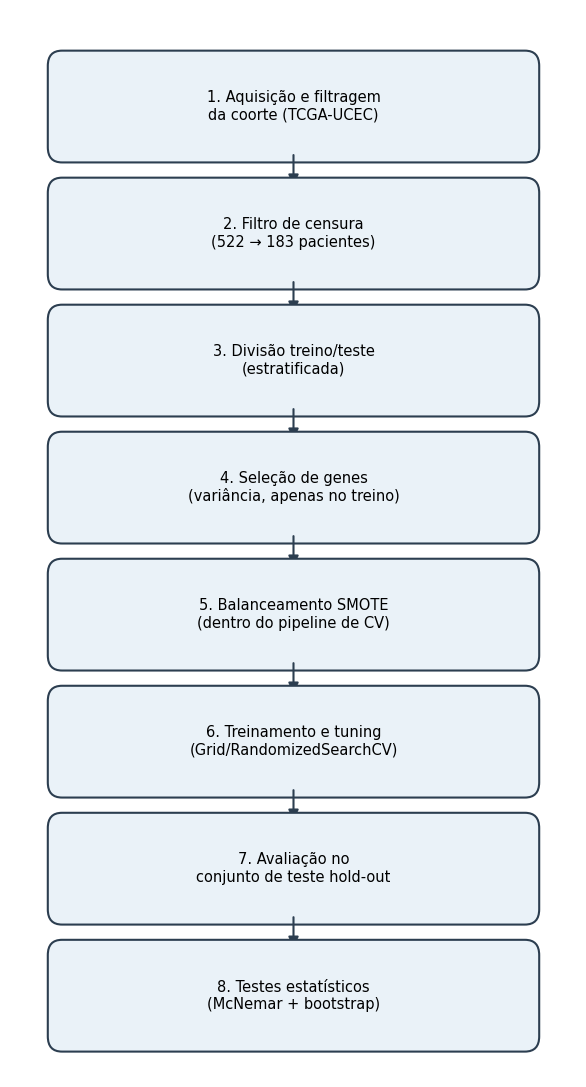

In [53]:
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

etapas = [
    "1. Aquisição e filtragem\nda coorte (TCGA-UCEC)",
    "2. Filtro de censura\n(522 → 183 pacientes)",
    "3. Divisão treino/teste\n(estratificada)",
    "4. Seleção de genes\n(variância, apenas no treino)",
    "5. Balanceamento SMOTE\n(dentro do pipeline de CV)",
    "6. Treinamento e tuning\n(Grid/RandomizedSearchCV)",
    "7. Avaliação no\nconjunto de teste hold-out",
    "8. Testes estatísticos\n(McNemar + bootstrap)",
]

fig, ax = plt.subplots(figsize=(6, 11))
box_h = 0.9
gap = 0.35
y = len(etapas) * (box_h + gap)

for i, texto in enumerate(etapas):
    y_atual = y - i * (box_h + gap)
    box = FancyBboxPatch((0.5, y_atual - box_h), 5, box_h,
                          boxstyle="round,pad=0.1,rounding_size=0.15",
                          linewidth=1.5, edgecolor="#2C3E50", facecolor="#EAF2F8")
    ax.add_patch(box)
    ax.text(3, y_atual - box_h / 2, texto, ha="center", va="center", fontsize=10.5)
    if i < len(etapas) - 1:
        seta = FancyArrowPatch((3, y_atual - box_h), (3, y_atual - box_h - gap),
                                arrowstyle="-|>", mutation_scale=15, color="#2C3E50", linewidth=1.5)
        ax.add_patch(seta)

ax.set_xlim(0, 6)
ax.set_ylim(0, y + 0.5)
ax.axis("off")
plt.tight_layout()
plt.savefig(caminho + "figura1_fluxograma_metodologia.png", dpi=300, bbox_inches="tight")
plt.show()

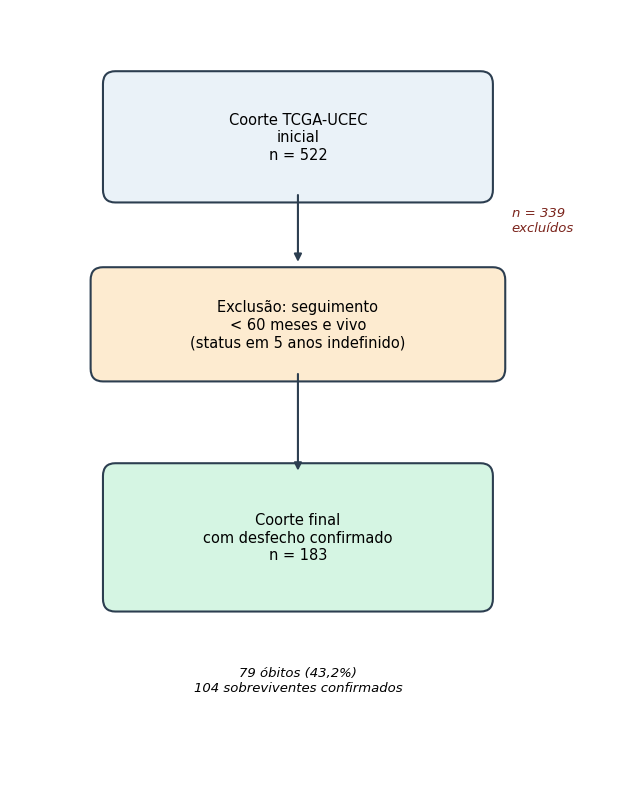

In [40]:

#Figura 3 — Diagrama do filtro de censura:
fig, ax = plt.subplots(figsize=(6.5, 8))

caixas_texto = [
    "Coorte TCGA-UCEC\ninicial\nn = 522",
    "Exclusão: seguimento\n< 60 meses e vivo\n(status em 5 anos indefinido)",
    "Coorte final\ncom desfecho confirmado\nn = 183",
]
y_positions = [7.5, 5.3, 2.8]
larguras = [4.5, 4.8, 4.5]
alturas = [1.3, 1.1, 1.5]
cores_fundo = ["#EAF2F8", "#FDEBD0", "#D5F5E3"]

for y_pos, texto, largura, altura, cor in zip(y_positions, caixas_texto, larguras, alturas, cores_fundo):
    box = FancyBboxPatch((3 - largura / 2, y_pos - altura / 2), largura, altura,
                          boxstyle="round,pad=0.12,rounding_size=0.15",
                          linewidth=1.5, edgecolor="#2C3E50", facecolor=cor)
    ax.add_patch(box)
    ax.text(3, y_pos, texto, ha="center", va="center", fontsize=10.5)

ax.annotate("", xy=(3, y_positions[1] + 0.7), xytext=(3, y_positions[0] - 0.65),
            arrowprops=dict(arrowstyle="-|>", color="#2C3E50", lw=1.5))
ax.annotate("", xy=(3, y_positions[2] + 0.75), xytext=(3, y_positions[1] - 0.55),
            arrowprops=dict(arrowstyle="-|>", color="#2C3E50", lw=1.5))

ax.text(5.6, 6.4, "n = 339\nexcluídos", fontsize=9.5, ha="left", style="italic", color="#7B241C")
ax.text(3, 1.0, "79 óbitos (43,2%)\n104 sobreviventes confirmados", ha="center", fontsize=9.5, style="italic")

ax.set_xlim(-0.5, 7); ax.set_ylim(0, 9); ax.axis("off")
plt.tight_layout()
plt.savefig(caminho + "figura3_diagrama_filtro_censura.png", dpi=300, bbox_inches="tight")
plt.show()

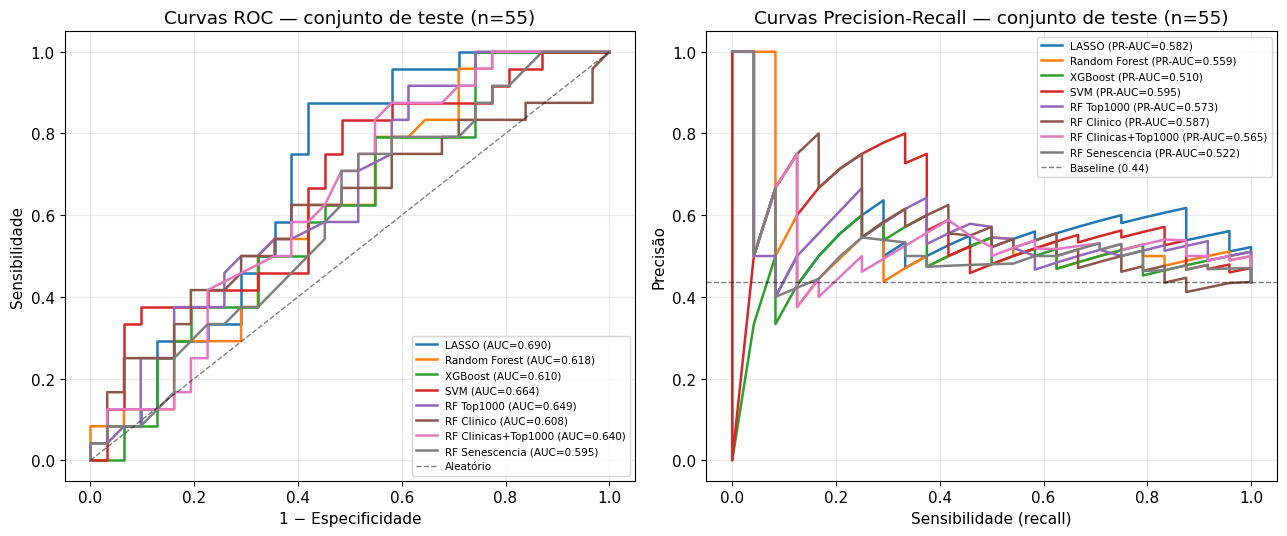

In [41]:
#Figura 2 — Curvas ROC e Precision-Recall
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for name, (y_pred, y_proba) in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    axes[0].plot(fpr, tpr, lw=1.8, label=f"{name} (AUC={results[name]['AUC-ROC']:.3f})")

    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    axes[1].plot(recall, precision, lw=1.8, label=f"{name} (PR-AUC={results[name]['PR-AUC']:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5, label="Aleatório")
axes[0].set_xlabel("1 − Especificidade"); axes[0].set_ylabel("Sensibilidade")
axes[0].set_title("Curvas ROC — conjunto de teste (n=55)")
axes[0].legend(fontsize=7.5, loc="lower right"); axes[0].grid(alpha=0.25)

baseline_pr = y_test.mean()
axes[1].axhline(baseline_pr, color="k", ls="--", lw=1, alpha=0.5, label=f"Baseline ({baseline_pr:.2f})")
axes[1].set_xlabel("Sensibilidade (recall)"); axes[1].set_ylabel("Precisão")
axes[1].set_title("Curvas Precision-Recall — conjunto de teste (n=55)")
axes[1].legend(fontsize=7.5, loc="upper right"); axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(caminho + "figura2_curvas_ROC_PR.png", dpi=300, bbox_inches="tight")
plt.show()


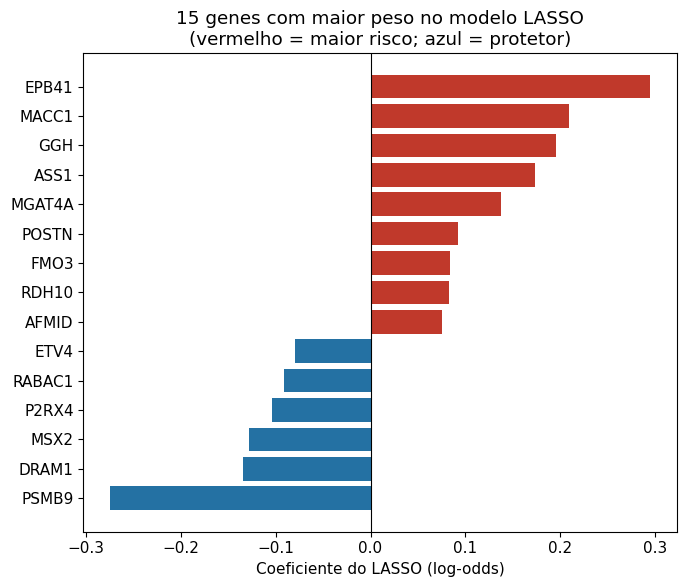

Total de genes com coeficiente não-nulo: 43 de 10164


In [42]:
#Figura 4 — Coeficientes do LASSO (usa lasso_coef da Célula 15):
coefs_nonzero = lasso_coef[lasso_coef != 0]
top15 = coefs_nonzero.reindex(coefs_nonzero.abs().sort_values(ascending=False).index[:15])
top15 = top15.sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
cores_barras = ["#C0392B" if v > 0 else "#2471A3" for v in top15.values]
ax.barh(top15.index, top15.values, color=cores_barras)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coeficiente do LASSO (log-odds)")
ax.set_title("15 genes com maior peso no modelo LASSO\n(vermelho = maior risco; azul = protetor)")
plt.tight_layout()
plt.savefig(caminho + "figura4_coeficientes_lasso.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Total de genes com coeficiente não-nulo: {len(coefs_nonzero)} de {X_train.shape[1]}")

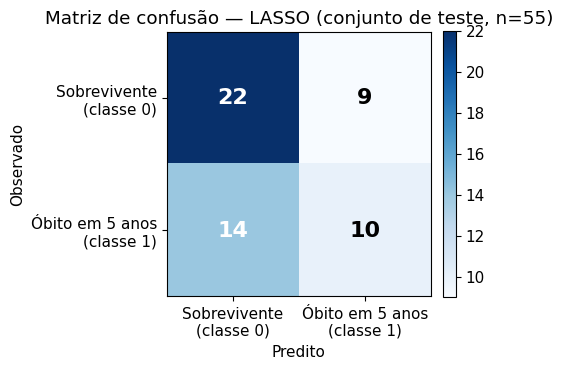

In [43]:
#Figura 5 — Matriz de confusão do LASSO
y_pred_lasso, y_proba_lasso = predictions['LASSO']
cm = confusion_matrix(y_test, y_pred_lasso)

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(cm, cmap="Blues")

labels = ["Sobrevivente\n(classe 0)", "Óbito em 5 anos\n(classe 1)"]
ax.set_xticks([0, 1]); ax.set_xticklabels(labels)
ax.set_yticks([0, 1]); ax.set_yticklabels(labels)
ax.set_xlabel("Predito"); ax.set_ylabel("Observado")
ax.set_title("Matriz de confusão — LASSO (conjunto de teste, n=55)")

for i in range(2):
    for j in range(2):
        cor_texto = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=16, color=cor_texto, fontweight="bold")

plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(caminho + "figura5_matriz_confusao_lasso.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Robustness to normalization: AWST vs log2(TPM+1)
Same genes, same split, same classifier. Normalization is the only difference. HGNC to Ensembl mapping uses mygene.info.

In [44]:
# ============================================================
# Etapa 16 (pre-requisito): CARREGAR MATRIZ TPM DO GDC
# Matriz pacientes x genes, colunas com IDs Ensembl versionados
# (ex.: ENSG00000141510.17) e indice com o mesmo PATIENT_ID do clin_f.
# ============================================================

tpm_data = pd.read_csv(caminho + 'mba_tpm_bruto.csv', index_col=0)
print(f"tpm_data: {tpm_data.shape}")
print(f"Pacientes da coorte valida presentes no TPM: {tpm_data.index.isin(pacientes_validos).sum()} de {len(pacientes_validos)}")


tpm_data: (539, 60660)
Pacientes da coorte valida presentes no TPM: 183 de 183


In [45]:
# ============================================================
# Etapa 16A: MAPEAR SIMBOLOS HGNC (AWST) PARA ENSEMBL (TPM)
# ============================================================

!pip install -q mygene

import mygene
import re

mg = mygene.MyGeneInfo()

awst_genes = list(exprData_valid.columns)  # 10164 simbolos
print(f"Consultando {len(awst_genes)} simbolos...")

query_result = mg.querymany(
    awst_genes,
    scopes='symbol',
    fields='ensembl.gene',
    species='human',
    as_dataframe=True,
    verbose=False
)

print(f"Retornado: {query_result.shape[0]} linhas")
print(query_result.head())

# ============================================================
# Etapa 16B: LIMPAR O MAPEAMENTO (1 simbolo -> 1 Ensembl)
# ============================================================

def extrair_ensembl(valor):
    # o campo pode vir como string unica, lista de dicts, ou NaN
    if isinstance(valor, list):
        ids = [v.get('gene') if isinstance(v, dict) else v for v in valor]
        return ids[0] if ids else None
    if isinstance(valor, dict):
        return valor.get('gene')
    return valor

query_result['ensembl_id'] = query_result['ensembl.gene'].apply(extrair_ensembl)
mapa = query_result['ensembl_id'].dropna()
mapa = mapa[~mapa.index.duplicated(keep='first')]  # 1 simbolo, 1 ensembl

print(f"Simbolos mapeados com sucesso: {len(mapa)} de {len(awst_genes)}")

symbol_to_ensembl = mapa.to_dict()

# ============================================================
# Etapa 16C: ALINHAR TPM (removendo sufixo de versao) E COMPARAR
# ============================================================

tpm_data_stripped = tpm_data.copy()
tpm_data_stripped.columns = [c.split('.')[0] for c in tpm_data_stripped.columns]
tpm_data_stripped = tpm_data_stripped.loc[:, ~tpm_data_stripped.columns.duplicated()]

top_genes_ensembl = {g: symbol_to_ensembl[g] for g in top_genes if g in symbol_to_ensembl}
genes_comuns_norm = [eid for eid in top_genes_ensembl.values() if eid in tpm_data_stripped.columns]

print(f"Genes do top1000 (AWST) com Ensembl encontrado no TPM: {len(genes_comuns_norm)}")

Consultando 10164 simbolos...
Retornado: 10265 linhas
           _id     _score     ensembl.gene  \
query                                        
A2ML1   144568  148.79999  ENSG00000166535   
A4GALT   53947  148.79999  ENSG00000128274   
AAAS      8086  148.79999              NaN   
AACS     65985  148.79999  ENSG00000081760   
AADAT    51166  148.79999  ENSG00000109576   

                                                  ensembl notfound  
query                                                               
A2ML1                                                 NaN      NaN  
A4GALT                                                NaN      NaN  
AAAS    [{'gene': 'ENSG00000094914'}, {'gene': 'ENSG00...      NaN  
AACS                                                  NaN      NaN  
AADAT                                                 NaN      NaN  
Simbolos mapeados com sucesso: 9545 de 10164
Genes do top1000 (AWST) com Ensembl encontrado no TPM: 948


In [52]:
# ============================================================
# Etapa 16D: MONTAR OS CONJUNTOS COMPARAVEIS (mesmos genes, mesmo split)
# ============================================================

pares_validos = [(sym, eid) for sym, eid in top_genes_ensembl.items() if eid in tpm_data_stripped.columns]
simbolos_validos = [p[0] for p in pares_validos]
ensembl_validos = [p[1] for p in pares_validos]

print(f"Pares simbolo-Ensembl validos para comparacao: {len(pares_validos)}")

# lado AWST: mesmos genes, ja normalizados por AWST
X_awst_cmp_train = X_train[simbolos_validos]
X_awst_cmp_test = X_test[simbolos_validos]

# lado TPM: mesmos genes (via Ensembl), com log2(TPM+1) -- padrao da literatura
tpm_valid_stripped = tpm_data_stripped.loc[pacientes_validos]

X_tpm_cmp_train_raw = tpm_valid_stripped.loc[idx_train, ensembl_validos]
X_tpm_cmp_test_raw = tpm_valid_stripped.loc[idx_test, ensembl_validos]

X_tpm_cmp_train = np.log2(X_tpm_cmp_train_raw.astype(float) + 1)
X_tpm_cmp_test = np.log2(X_tpm_cmp_test_raw.astype(float) + 1)

print(f"AWST (comparacao): treino {X_awst_cmp_train.shape}, teste {X_awst_cmp_test.shape}")
print(f"TPM log2 (comparacao): treino {X_tpm_cmp_train.shape}, teste {X_tpm_cmp_test.shape}")

# checagem rapida de sanidade nos valores
print("\nAWST - resumo estatistico (primeiro gene):", X_awst_cmp_train.iloc[:, 0].describe()[['mean','std','min','max']].to_dict())
print("TPM log2 - resumo estatistico (primeiro gene):", X_tpm_cmp_train.iloc[:, 0].describe()[['mean','std','min','max']].to_dict())


# ============================================================
# Etapa 16E: COMPARAR AWST vs TPM (mesmos genes, mesmo split, sem vazamento)
# ============================================================

def avaliar_normalizacao(X_tr, y_tr, X_te, y_te, valores_C):
    melhor_auc, melhor_c = -1, None
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    for C in valores_C:
        cv_scores = []
        for tr_i, val_i in skf.split(X_tr, y_tr):
            pipe = ImbPipeline([
                ('smote', SMOTE(random_state=RANDOM_STATE)),
                ('clf', LogisticRegression(penalty='l1', solver='liblinear', C=C,
                                            max_iter=5000, random_state=RANDOM_STATE))
            ])
            pipe.fit(X_tr.iloc[tr_i], y_tr.iloc[tr_i])
            proba = pipe.predict_proba(X_tr.iloc[val_i])[:, 1]
            cv_scores.append(roc_auc_score(y_tr.iloc[val_i], proba))
        auc_cv = np.mean(cv_scores)
        if auc_cv > melhor_auc:
            melhor_auc, melhor_c = auc_cv, C

    pipe_final = ImbPipeline([
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(penalty='l1', solver='liblinear', C=melhor_c,
                                    max_iter=5000, random_state=RANDOM_STATE))
    ])
    pipe_final.fit(X_tr, y_tr)
    auc_teste = roc_auc_score(y_te, pipe_final.predict_proba(X_te)[:, 1])
    return melhor_c, melhor_auc, auc_teste

valores_C = [0.01, 0.1, 1, 10]

print("Avaliando AWST...")
c_awst, auc_cv_awst, auc_teste_awst = avaliar_normalizacao(
    X_awst_cmp_train, y_train, X_awst_cmp_test, y_test, valores_C
)
print("Avaliando TPM (log2)...")
c_tpm, auc_cv_tpm, auc_teste_tpm = avaliar_normalizacao(
    X_tpm_cmp_train, y_train, X_tpm_cmp_test, y_test, valores_C
)

print("\n" + "="*50)
print(f"COMPARACAO DE NORMALIZACAO (mesmos {len(pares_validos)} genes, mesmo split)")
print("="*50)
print(f"AWST:      melhor C={c_awst}, AUC CV={auc_cv_awst:.4f}, AUC teste={auc_teste_awst:.4f}")
print(f"TPM log2:  melhor C={c_tpm}, AUC CV={auc_cv_tpm:.4f}, AUC teste={auc_teste_tpm:.4f}")

resultados_norm = {
    'AWST': {'melhor_C': c_awst, 'AUC_cv': auc_cv_awst, 'AUC_teste': auc_teste_awst},
    'TPM_log2': {'melhor_C': c_tpm, 'AUC_cv': auc_cv_tpm, 'AUC_teste': auc_teste_tpm},
    'n_genes_comparados': len(pares_validos)
}
with open(caminho + 'resultados_comparacao_normalizacao.json', 'w') as f:
    json.dump(resultados_norm, f, indent=4)
print("\nSalvo em resultados_comparacao_normalizacao.json")

Pares simbolo-Ensembl validos para comparacao: 948
AWST (comparacao): treino (128, 948), teste (55, 948)
TPM log2 (comparacao): treino (128, 948), teste (55, 948)

AWST - resumo estatistico (primeiro gene): {'mean': 0.9378942936302465, 'std': 2.3884152254131443, 'min': -1.99865101539632, 'max': 3.10418973264575}
TPM log2 - resumo estatistico (primeiro gene): {'mean': 3.412461347253421, 'std': 2.1117793654666457, 'min': 0.011495638837829437, 'max': 8.41319632519114}
Avaliando AWST...
Avaliando TPM (log2)...

COMPARACAO DE NORMALIZACAO (mesmos 948 genes, mesmo split)
AWST:      melhor C=0.1, AUC CV=0.6203, AUC teste=0.6008
TPM log2:  melhor C=1, AUC CV=0.6934, AUC teste=0.5995

Salvo em resultados_comparacao_normalizacao.json


In [47]:
# ============================================================
# Etapa 16F: BOOTSTRAP - A DIFERENCA TPM vs AWST E SIGNIFICATIVA?
# ============================================================

pipe_awst_final = ImbPipeline([
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('clf', LogisticRegression(penalty='l1', solver='liblinear', C=c_awst,
                                max_iter=5000, random_state=RANDOM_STATE))
])
pipe_awst_final.fit(X_awst_cmp_train, y_train)
proba_awst = pipe_awst_final.predict_proba(X_awst_cmp_test)[:, 1]

pipe_tpm_final = ImbPipeline([
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('clf', LogisticRegression(penalty='l1', solver='liblinear', C=c_tpm,
                                max_iter=5000, random_state=RANDOM_STATE))
])
pipe_tpm_final.fit(X_tpm_cmp_train, y_train)
proba_tpm = pipe_tpm_final.predict_proba(X_tpm_cmp_test)[:, 1]

rng = np.random.RandomState(RANDOM_STATE)
y_test_arr = y_test.values
n_test = len(y_test_arr)
diffs = []
tentativas = 0
while len(diffs) < 1000 and tentativas < 3000:
    tentativas += 1
    idx = rng.choice(n_test, size=n_test, replace=True)
    y_boot = y_test_arr[idx]
    if len(np.unique(y_boot)) < 2:
        continue
    auc_tpm_b = roc_auc_score(y_boot, proba_tpm[idx])
    auc_awst_b = roc_auc_score(y_boot, proba_awst[idx])
    diffs.append(auc_tpm_b - auc_awst_b)

diffs = np.array(diffs)
ci_lower, ci_upper = np.percentile(diffs, [2.5, 97.5])
p_boot = 2 * min(np.mean(diffs <= 0), np.mean(diffs >= 0))

print(f"Diferenca TPM - AWST: {auc_teste_tpm - auc_teste_awst:.4f}")
print(f"IC 95%: [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"Bootstrap p-valor: {p_boot:.4f}")

Diferenca TPM - AWST: -0.0013
IC 95%: [-0.1499, 0.1327]
Bootstrap p-valor: 0.9560


In [48]:
# ============================================================
# Etapa 16G: PREPARAR CONJUNTO DE GENES COMUM COMPLETO
# (todos os genes mapeados entre AWST e TPM, sem filtro de variancia)
# ============================================================

genes_comuns_completo = [(sym, eid) for sym, eid in symbol_to_ensembl.items()
                          if sym in exprData_valid.columns and eid in tpm_data_stripped.columns]
simbolos_completo = [p[0] for p in genes_comuns_completo]
ensembl_completo = [p[1] for p in genes_comuns_completo]
print(f"Genes mapeados e presentes nas duas matrizes: {len(genes_comuns_completo)}")

X_train_awst_full = X_train[simbolos_completo]
X_test_awst_full = X_test[simbolos_completo]

tpm_valid_full = tpm_data_stripped.loc[pacientes_validos]
X_train_tpm_full_raw = tpm_valid_full.loc[idx_train, ensembl_completo]
X_test_tpm_full_raw = tpm_valid_full.loc[idx_test, ensembl_completo]

X_train_tpm_full = np.log2(X_train_tpm_full_raw.astype(float) + 1)
X_test_tpm_full = np.log2(X_test_tpm_full_raw.astype(float) + 1)

# renomear colunas do TPM para o simbolo correspondente, so para leitura mais facil depois
X_train_tpm_full.columns = simbolos_completo
X_test_tpm_full.columns = simbolos_completo

print(f"AWST completo: treino {X_train_awst_full.shape}, teste {X_test_awst_full.shape}")
print(f"TPM completo:  treino {X_train_tpm_full.shape}, teste {X_test_tpm_full.shape}")


# ============================================================
# Etapa 16H: LASSO COMPLETO -- AWST vs TPM log2 (mesmo conjunto de genes, sem filtro previo)
# Usa a mesma rigidez metodologica da Tabela 1 principal (GridSearchCV completo).
# ============================================================

def rodar_lasso_completo(X_tr, y_tr, X_te, y_te, label):
    pipe = ImbPipeline([
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(penalty='l1', solver='liblinear', max_iter=5000, random_state=RANDOM_STATE))
    ])
    param = {'clf__C': [0.001, 0.01, 0.1, 1, 10, 100]}
    grid = GridSearchCV(pipe, param, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=1)

    start = time.time()
    grid.fit(X_tr, y_tr)
    print(f"[{label}] concluido em {time.time()-start:.2f}s")

    proba = grid.predict_proba(X_te)[:, 1]
    pred = grid.predict(X_te)
    auc_teste = roc_auc_score(y_te, proba)

    print(f"[{label}] Melhor C: {grid.best_params_['clf__C']}")
    print(f"[{label}] AUC validacao cruzada: {grid.best_score_:.4f}")
    print(f"[{label}] AUC teste: {auc_teste:.4f}")
    print(f"[{label}] Matriz de confusao:\n{confusion_matrix(y_te, pred)}")

    return grid, proba

grid_awst_full, proba_awst_full = rodar_lasso_completo(
    X_train_awst_full, y_train, X_test_awst_full, y_test, "AWST completo"
)
grid_tpm_full, proba_tpm_full = rodar_lasso_completo(
    X_train_tpm_full, y_train, X_test_tpm_full, y_test, "TPM log2 completo"
)


# ============================================================
# Etapa 16I: BOOTSTRAP -- DIFERENCA E SIGNIFICATIVA AGORA?
# ============================================================

rng = np.random.RandomState(RANDOM_STATE)
y_test_arr = y_test.values
n_test = len(y_test_arr)
diffs = []
tentativas = 0
while len(diffs) < 1000 and tentativas < 3000:
    tentativas += 1
    idx = rng.choice(n_test, size=n_test, replace=True)
    y_boot = y_test_arr[idx]
    if len(np.unique(y_boot)) < 2:
        continue
    auc_tpm_b = roc_auc_score(y_boot, proba_tpm_full[idx])
    auc_awst_b = roc_auc_score(y_boot, proba_awst_full[idx])
    diffs.append(auc_tpm_b - auc_awst_b)

diffs = np.array(diffs)
ci_lower, ci_upper = np.percentile(diffs, [2.5, 97.5])
p_boot = 2 * min(np.mean(diffs <= 0), np.mean(diffs >= 0))

diff_puntual = roc_auc_score(y_test, proba_tpm_full) - roc_auc_score(y_test, proba_awst_full)
print(f"Diferenca TPM - AWST (genes completos): {diff_puntual:.4f}")
print(f"IC 95%: [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"Bootstrap p-valor: {p_boot:.4f}")

Genes mapeados e presentes nas duas matrizes: 9526
AWST completo: treino (128, 9526), teste (55, 9526)
TPM completo:  treino (128, 9526), teste (55, 9526)
Fitting 5 folds for each of 6 candidates, totalling 30 fits
[AWST completo] concluido em 56.71s
[AWST completo] Melhor C: 100
[AWST completo] AUC validacao cruzada: 0.7384
[AWST completo] AUC teste: 0.6586
[AWST completo] Matriz de confusao:
[[20 11]
 [15  9]]
Fitting 5 folds for each of 6 candidates, totalling 30 fits
[TPM log2 completo] concluido em 36.31s
[TPM log2 completo] Melhor C: 1
[TPM log2 completo] AUC validacao cruzada: 0.7669
[TPM log2 completo] AUC teste: 0.6895
[TPM log2 completo] Matriz de confusao:
[[22  9]
 [10 14]]
Diferenca TPM - AWST (genes completos): 0.0309
IC 95%: [-0.0862, 0.1493]
Bootstrap p-valor: 0.6000


## 9. Appendix: risk scores on GSE106191 (exploratory)
Not part of the thesis results. GSE106191 is cited in the thesis limitations as the only suitable public cohort found, but it has no survival annotation in GEO, so external AUC cannot be computed. Scores are generated only to inspect their distribution.

In [49]:
# ============================================================
# Etapa 17: MODELO LASSO "ENXUTO" PARA VALIDACAO EXTERNA
# Restrito aos genes que existem na GSE106191 -- decidido ANTES
# do treino, para nao precisar imputar/zerar genes ausentes.
# ============================================================

gse_exprs = pd.read_csv(caminho + 'mba_gse106191_exprs_symbols.csv', index_col=0)
gse_pheno = pd.read_csv(caminho + 'mba_gse106191_pheno.csv', index_col=0)
print(f"GSE106191 - expressao: {gse_exprs.shape}, pheno: {gse_pheno.shape}")

# tratar possiveis simbolos de gene duplicados no indice (media das linhas)
if gse_exprs.index.duplicated().any():
    n_dup = gse_exprs.index.duplicated().sum()
    print(f"Aviso: {n_dup} simbolos de gene duplicados na GSE106191, calculando media.")
    gse_exprs = gse_exprs.groupby(gse_exprs.index).mean()

genes_lasso_lista = genes_lasso.index.tolist()
genes_enxuto = [g for g in genes_lasso_lista if g in gse_exprs.index]
print(f"Genes do LASSO original ({len(genes_lasso_lista)}) presentes na GSE106191: {len(genes_enxuto)}")

if len(genes_enxuto) < 20:
    print("Poucos genes em comum -- validacao externa pouco confiavel. Considere reportar isso como limitacao em vez de prosseguir.")

X_enxuto_train = X_train[genes_enxuto]
X_enxuto_test = X_test[genes_enxuto]

pipe_lasso_enxuto = ImbPipeline([
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('clf', LogisticRegression(penalty='l1', solver='liblinear', C=grid_lasso.best_params_['clf__C'],
                                max_iter=5000, random_state=RANDOM_STATE))
])
pipe_lasso_enxuto.fit(X_enxuto_train, y_train)

auc_enxuto_interno = roc_auc_score(y_test, pipe_lasso_enxuto.predict_proba(X_enxuto_test)[:, 1])
print(f"AUC do modelo enxuto no teste interno (TCGA): {auc_enxuto_interno:.4f}")

joblib.dump(pipe_lasso_enxuto, caminho + 'modelo_lasso_enxuto.joblib')
joblib.dump(genes_enxuto, caminho + 'genes_lasso_enxuto.joblib')
print("Modelo enxuto e lista de genes salvos.")


GSE106191 - expressao: (23520, 97), pheno: (97, 34)
Genes do LASSO original (43) presentes na GSE106191: 43
AUC do modelo enxuto no teste interno (TCGA): 0.6949
Modelo enxuto e lista de genes salvos.


In [50]:
# ============================================================
# Etapa 18: INSPECIONAR VARIAVEIS DA GSE106191 ANTES DE MAPEAR
# (nao adivinhe o nome/formato -- confira primeiro)
# ============================================================

print("Colunas disponiveis no pheno da GSE106191:")
print(gse_pheno.columns.tolist())

colunas_candidatas = [c for c in gse_pheno.columns
                       if any(k in c.lower() for k in ['status', 'death', 'surv', 'vital', 'time', 'day', 'month'])]
print(f"\nColunas candidatas a variavel de desfecho: {colunas_candidatas}")

for c in colunas_candidatas:
    print(f"\nValores unicos em '{c}':")
    print(gse_pheno[c].unique()[:15])

Colunas disponiveis no pheno da GSE106191:
['title', 'geo_accession', 'status', 'submission_date', 'last_update_date', 'type', 'channel_count', 'source_name_ch1', 'organism_ch1', 'characteristics_ch1', 'characteristics_ch1.1', 'characteristics_ch1.2', 'molecule_ch1', 'extract_protocol_ch1', 'label_ch1', 'label_protocol_ch1', 'taxid_ch1', 'hyb_protocol', 'scan_protocol', 'data_processing', 'platform_id', 'contact_name', 'contact_email', 'contact_institute', 'contact_address', 'contact_city', 'contact_state', 'contact_zip/postal_code', 'contact_country', 'supplementary_file', 'data_row_count', 'age:ch1', 'Sex:ch1', 'tissue:ch1']

Colunas candidatas a variavel de desfecho: ['status']

Valores unicos em 'status':
['Public on Sep 13 2019']


Genes do modelo enxuto disponíveis na GSE106191: 43


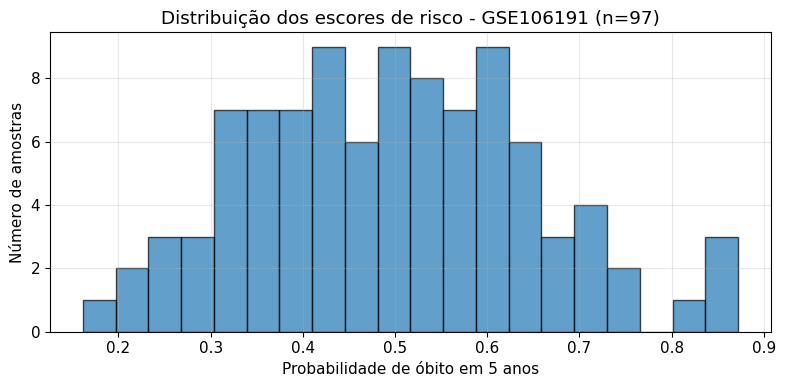

Escores de risco gerados e salvos.
Não foi possível calcular AUC externa porque a GSE106191 não possui dados de sobrevida disponíveis.


In [51]:
# ============================================================
# Etapa 19: VALIDACAO EXTERNA (GSE106191) - APENAS ESCORES
# ============================================================

# Carregar o modelo enxuto e a lista de genes
pipe_lasso_enxuto = joblib.load(caminho + 'modelo_lasso_enxuto.joblib')
genes_enxuto = joblib.load(caminho + 'genes_lasso_enxuto.joblib')

# Carregar a coorte externa
gse_exprs = pd.read_csv(caminho + 'mba_gse106191_exprs_symbols.csv', index_col=0)
gse_pheno = pd.read_csv(caminho + 'mba_gse106191_pheno.csv', index_col=0)

# Tratar duplicatas de genes
if gse_exprs.index.duplicated().any():
    gse_exprs = gse_exprs.groupby(gse_exprs.index).mean()

# Verificar genes disponíveis na coorte externa
genes_externos = [g for g in genes_enxuto if g in gse_exprs.index]
print(f"Genes do modelo enxuto disponíveis na GSE106191: {len(genes_externos)}")

if len(genes_externos) == 0:
    print("Nenhum gene do modelo enxuto está presente na coorte externa. Validação impossível.")
else:
    # Preparar X externo (apenas os genes disponíveis)
    X_external = gse_exprs.loc[genes_externos].T  # amostras nas linhas

    # Padronizar (z-score) a coorte externa separadamente
    from sklearn.preprocessing import StandardScaler
    scaler_gse = StandardScaler()
    X_external_z = pd.DataFrame(
        scaler_gse.fit_transform(X_external),
        index=X_external.index,
        columns=genes_externos
    )

    # Preencher com zeros os genes do modelo que não estão na coorte (se houver)
    # Mas como limitamos aos genes_externos, não há zeros.
    # Se quiser manter todos os genes do modelo enxuto, você pode criar uma matriz de zeros
    # com as mesmas colunas do modelo e preencher apenas os que existem.
    # Vou manter só os genes existentes (mais honesto).

    # Gerar escores de risco
    y_proba_external = pipe_lasso_enxuto.predict_proba(X_external_z)[:, 1]

    # Salvar escores
    risco_df = pd.DataFrame({
        'Sample': X_external_z.index,
        'Probabilidade_Risco': y_proba_external
    })
    risco_df.to_csv(caminho + 'gse106191_escores_risco_corrigido.csv', index=False)

    # Distribuição dos escores
    plt.figure(figsize=(8, 4))
    plt.hist(risco_df['Probabilidade_Risco'], bins=20, edgecolor='black', alpha=0.7)
    plt.xlabel('Probabilidade de óbito em 5 anos')
    plt.ylabel('Número de amostras')
    plt.title(f'Distribuição dos escores de risco - GSE106191 (n={len(risco_df)})')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(caminho + 'escores_risco_gse106191_corrigido.png', dpi=300)
    plt.show()

    print("Escores de risco gerados e salvos.")
    print("Não foi possível calcular AUC externa porque a GSE106191 não possui dados de sobrevida disponíveis.")